In [ ]:
import pandas as pd
df = pd.read_csv('heart.csv')
df = df.dropna()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Age            50 non-null     int64
 1   Gender         50 non-null     str  
 2   Education      50 non-null     str  
 3   Income         50 non-null     int64
 4   Smoker         50 non-null     str  
 5   Cholesterol    50 non-null     int64
 6   Heart_Disease  50 non-null     str  
dtypes: int64(3), str(4)
memory usage: 2.9 KB


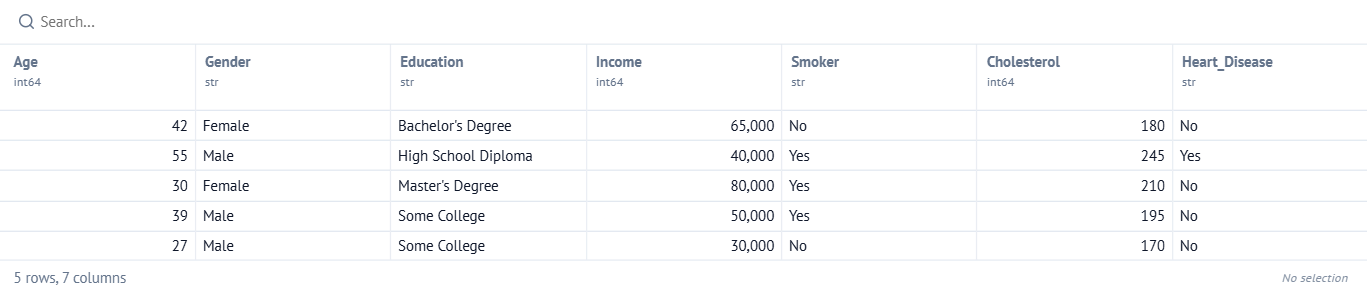

In [ ]:
target_col = 'Heart_Disease'
df.head()

In [ ]:
X = df.drop(target_col, axis=1)
Y = df[target_col]
X = pd.get_dummies(X, drop_first=True)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

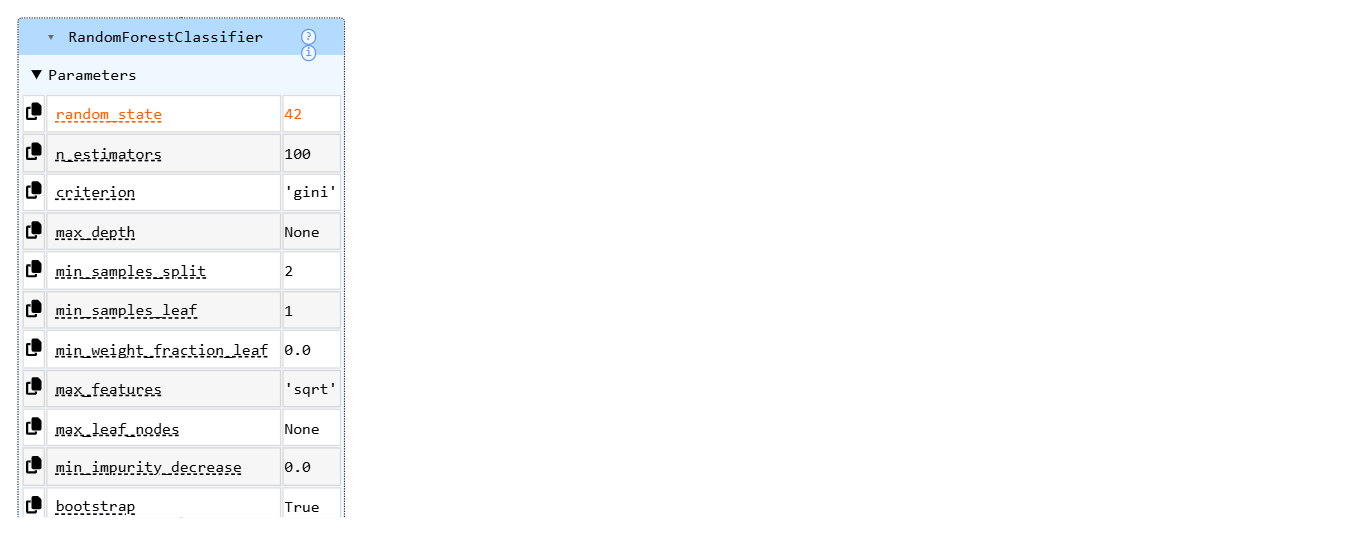

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

log_model = LogisticRegression(max_iter=2000)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

log_model.fit(X_train, Y_train)
rf_model.fit(X_train, Y_train)

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

Y_pred_log = log_model.predict(X_test)
Y_pred_rf = rf_model.predict(X_test)

print("--- Précision (Accuracy) ---")
print(f"Régression Logistique : {accuracy_score(Y_test, Y_pred_log):.3f}")
print(f"Random Forest :         {accuracy_score(Y_test, Y_pred_rf):.3f}\n")

print("--- Rapport de classification (Random Forest) ---")
print(classification_report(Y_test, Y_pred_rf))

--- Précision (Accuracy) ---
Régression Logistique : 1.000
Random Forest :         1.000

--- Rapport de classification (Random Forest) ---
              precision    recall  f1-score   support

          No       1.00      1.00      1.00         6
         Yes       1.00      1.00      1.00         4

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10



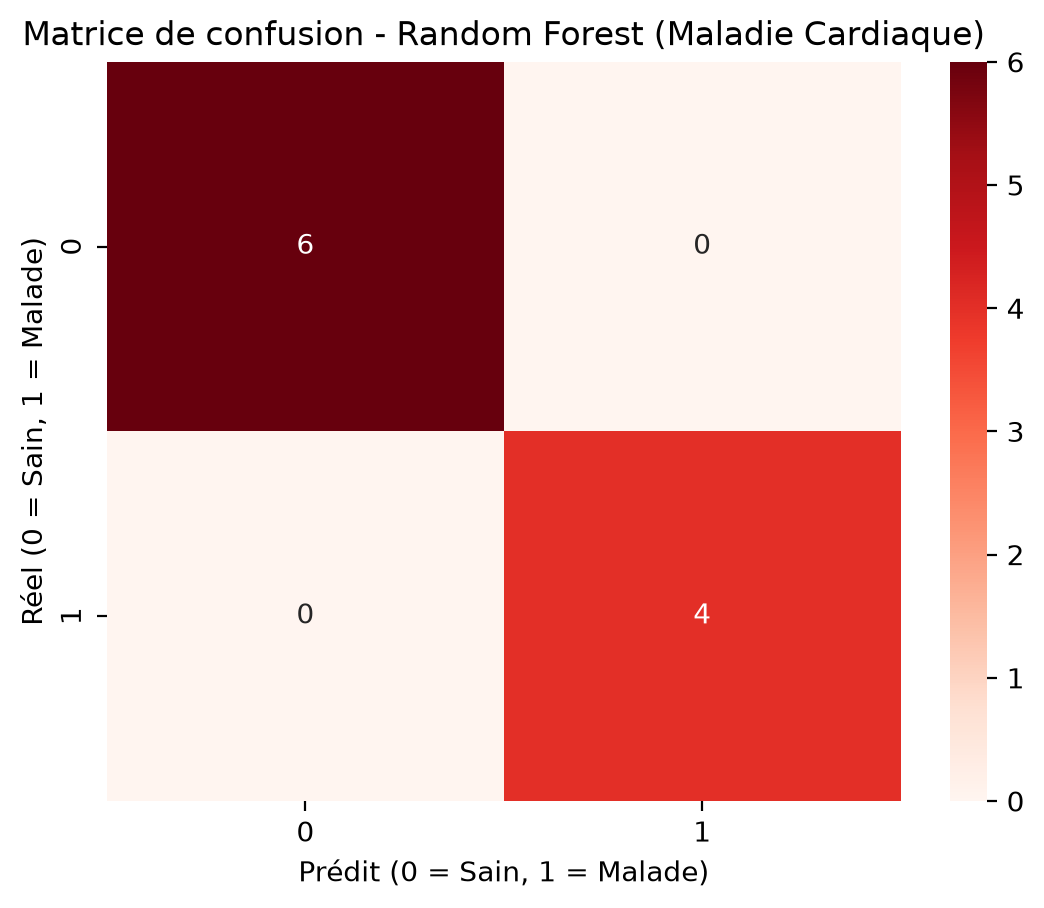

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(Y_test, Y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds')
plt.title('Matrice de confusion - Random Forest (Maladie Cardiaque)')
plt.xlabel('Prédit (0 = Sain, 1 = Malade)')
plt.ylabel('Réel (0 = Sain, 1 = Malade)')
plt.show()

In [ ]:
CONCLUSION => 

"""
Notre modèle affiche un score parfait de 100 %. Mais ce résultat n'est pas fiable. Le fichier contient beaucoup trop peu de données.

Nous avons testé le modèle sur seulement 10 personnes. Avec si peu de tests, l'ordinateur a juste de la chance. Il mémorise les réponses au lieu de vraiment apprendre.

"""